# Controlled MolMIM with Custom Oracle - QSAR 01

In [1]:
#!pip install cma matplotlib numpy pandas rdkit

In [2]:
#!pip install msal

In [3]:
import cma
import json
import matplotlib.pyplot as plt
import numpy as np
import requests
from IPython.display import display, clear_output
from rdkit import Chem
from rdkit.Chem import Draw
from rdkit.Chem.QED import qed
from rdkit.Chem.Crippen import MolLogP
from rdkit.Chem.AllChem import GetMorganFingerprintAsBitVect
from rdkit.DataStructs import TanimotoSimilarity
from rdkit import RDLogger                                                                                               
RDLogger.DisableLog('rdApp.*')


### Define the NIM host
To get started, we'll define our NIM host and the NIM endpoints we'll use in the following cells.

 - `/sampling` - Perform random sampling around a seed SMILES to define a starting population
 - `/hidden` - Generate the hidden state encoding for a set of input SMILES
 - `/decode` - Decode hidden state encodings to return a set of SMILES

In [4]:
!docker ps -a
# In case you want to stop the container -> !docker stop molmim

CONTAINER ID   IMAGE                                                       COMMAND                  CREATED       STATUS       PORTS                                                           NAMES
a97ff4bc9968   841162696343.dkr.ecr.us-east-1.amazonaws.com/molmim:1.0.0   "/opt/nvidia/nvidia_…"   5 hours ago   Up 5 hours   6006/tcp, 8888/tcp, 0.0.0.0:8000->8000/tcp, :::8000->8000/tcp   molmim-prod


In [5]:
nim_host="127.0.0.1"
port="8000"
sampling_url=f"http://{nim_host}:{port}/sampling"
hidden_url=f"http://{nim_host}:{port}/hidden"
decode_url=f"http://{nim_host}:{port}/decode"

Let's run a health check on our NIM:

In [6]:
!curl {nim_host}:{port}/v1/health/ready

{"status":"ready"}

# define seeds

In [7]:
# first Bayer Seed
m1 = "COC(=O)CCNC(=O)C1(C)CC(c2cc(Cl)cc(Cl)c2)=NO1"
m1_name = "BCS-CN20332"

In [8]:
# second seed
m2 = "CC1=NN(CC)C=C1CNC(=O)C1CC(=NO1)C1C=C(Br)C=CC=1"
m2_name = "BCS-CE65417"

In [9]:
m3 = "CC(C)CC1=CC=C(C=C1)C(C)C(O)=O"
m3_name ="ibuprofen"

In [10]:
#### define the mol to use forth
m_seed = m2
m_seed_name = m2_name

# Bayer Custom Scoring function

In [11]:
from by_scorer_new import MoleculeScorer

# create scorer with two or more metrics
# here we use a QSAR model (AIH metric) with similarity (tanimoto-fingerprint) as co-metric
scorer = MoleculeScorer.create_scorer(
    use_qsar_hsec=False,
    use_qsar_aih=True,
    use_qed = False,
    use_similarity=True,
    similarity_weight= 1.0,
    similarity_threshold= 0.4,
    qsar_aih_threshold = 0.9,
    qsar_aih_weight= 1.0
)

# overrride currently with sim only
scorer = MoleculeScorer.create_scorer(
    use_qsar_hsec=False,
    use_qsar_aih=False,
    use_qed = False,
    use_similarity=True,
    similarity_weight=1.0,
    similarity_threshold=1.0,
)

In [12]:

# Test molecule scoring and access predictions and metrics
test_result = scorer.score([m_seed], reference_smiles=m_seed)
seed_score = test_result.norm_qsar_aih_scores[0]
print(f"QSAR-SIP: {test_result.qsar_aih_scores}")
print(f"QSAR-SIP Normalized: {test_result.norm_qsar_aih_scores}")
print(f"Combined Score normalized: {test_result.combined_scores}")

#~now scoring~#
#~Done scoring~#
QSAR-SIP: [0.0]
QSAR-SIP Normalized: [0.09090909090909091]
Combined Score normalized: [-1.]


# First an example using random sampling around the initial seed

In [13]:
# Define a starting array of seed SMIs
mol = Chem.MolFromSmiles(m_seed)

starting_smiles = [
    m_seed,
    m_seed,
    m_seed,
    m_seed,
    m_seed,
    m_seed,
    m_seed,
    m_seed,
    m_seed,
    m_seed,
    m_seed,
    m_seed,
    m_seed,
    m_seed
]
print(len(starting_smiles))

generated_smiles = []
tanimoto_scores = []
logp_scores = []
sampling_summary = {}

# Create the request data
for smi in starting_smiles:
    data = {
        'sequences': [smi],
        'beam_size': 10,
        'num_molecules': 10, # reduce if more starting molecules are used
        'scaled_radius': 2.0,
    }

    # Send the request and get the response
    headers = {'Content-Type': 'application/json'}
    response = requests.post(sampling_url, headers=headers, json=data)
    
    # Parse the response as JSON
    response_json = json.loads(response.text)
    
    # Extract the generated SMILES strings
    generated_molecules = response_json['generated'][0]
    
    # Filter out invalid SMILES strings
    valid_smiles = [m for m in generated_molecules if Chem.MolFromSmiles(m) is not None]
    generated_smiles.extend(valid_smiles)

results = scorer.score(generated_smiles, reference_smiles=m_seed)

# Sampling summary - valid smiles count, average Tanimoto and QED scores
sampling_summary['valid_smiles'] = len(generated_smiles)
sampling_summary['Score_Metric'] = np.mean(results.norm_qsar_hsec_scores) ## CHANGE IF METRIC CHANGES
sampling_summary['Similarity'] = np.mean(results.similarity_scores)

print(f"Valid SMILES = {sampling_summary['valid_smiles']}, mean score = {sampling_summary['Score_Metric']}, mean similarity {sampling_summary['Similarity']}")


14
#~now scoring~#
#~Done scoring~#
Valid SMILES = 139, mean score = 0.09090909090909093, mean similarity 0.1460436496488003


# Plot the scores 
of the randomly sampled candidates in our search space.

(0.0, 1.0)

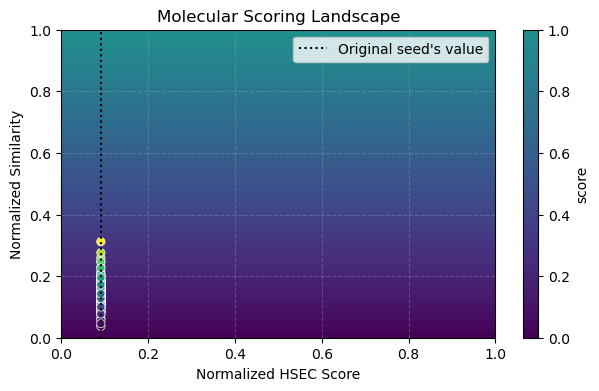

In [14]:
# get normalized values of molecules from scorer
x_scores = results.norm_qsar_aih_scores   ## Already normalized 0-1
y_scores = results.norm_similarity_scores  ## Already normalized 0-1

# set color for scatter
color = -1*results.combined_scores


# Create a uniform grid from 0 to 1
deltas = np.linspace(0, 1, 100)
Xgrid, Ygrid = np.meshgrid(deltas, deltas)

# Calculate scores across the entire grid
grid_scores, _ = scorer.score_from_properties(similarity_values=Ygrid, qsar_aih_values=Xgrid*scorer.aih_max + scorer.aih_min)

# Plot everything
plt.figure(figsize=(7, 4))

# Plot contour background (0-1 range)
contour = plt.contourf(Xgrid, Ygrid, -1*grid_scores, levels=100, cmap='viridis', vmin=0, vmax=2.0)
plt.colorbar(label='score', ticks=np.linspace(0,2,11))

# Plot reference line for seed value
plt.plot([seed_score, seed_score], [0, 1], linestyle=':', c='k', label="Original seed's value")

# Plot data points (already normalized)
plt.scatter(x_scores, y_scores, c=color, edgecolor='white', linewidths=0.5, cmap='viridis')

plt.xlabel("Normalized HSEC Score") 
plt.ylabel("Normalized Similarity")
plt.title("Molecular Scoring Landscape")
plt.legend()
plt.grid(alpha=0.3, linestyle='--')
plt.xlim(0, 1)
plt.ylim(0, 1)



## Controlled Generation with CMA-ES and the custom oracle

### Generate hidden state encoding for the imatinib seed to initialize CMA-ES

To start the CMA-ES optimization process, we first seed the optimizer with the hidden state encoding for our imatinib seed molecule using the `/hidden` endpoint.

In [15]:
# First calculate a hidden state representation of our seed, imatinib.
headers = {
    'accept': 'application/json',
    'Content-Type': 'application/json'
}
data = {
    "sequences": [m_seed],
}

# Get the response from the server
response = requests.post(hidden_url, headers=headers, json=data)
imatinib_hidden = np.squeeze(np.array(response.json()["hiddens"]))

# We can use this seed hidden state as a starting point for our CMA-ES optimizer
popsize = sampling_summary['valid_smiles']
sigma=1.0

# Initialize with zeros or the hidden state encoding for imatinib
#optimizer = cma.CMAEvolutionStrategy(np.zeros(imatinib_hidden.size, dtype=np.float32), sigma, {'popsize': popsize})
optimizer = cma.CMAEvolutionStrategy(imatinib_hidden, sigma, {'popsize': popsize/2})

(34_w,69)-aCMA-ES (mu_w=18.9,w_1=11%) in dimension 512 (seed=572878, Wed Mar 19 12:58:57 2025)


Now that we've initialized the CMA-ES optimizer, we can generate and decode an initial set of trial encodings using the `/decode` endpoint.

In [16]:
# Generate and decode a set of initial trial encodings with CMA-ESecode trial encodings
trial_encodings=optimizer.ask(popsize)

headers = {
    'accept': 'application/json',
    'Content-Type': 'application/json'
}
hiddens_array = np.expand_dims(np.array(trial_encodings), axis=1)
hiddens_json = {"hiddens":hiddens_array.tolist(),
                "mask": [[True] for i in range(hiddens_array.shape[0])]}


response = requests.post(decode_url, headers=headers, json=hiddens_json)
molecules = list(dict.fromkeys(response.json()['generated']))

We can then calculate the scores for this trial population and plot the results in our search space.

In [17]:
# score current draw
results = scorer.score(molecules, reference_smiles=m_seed)

# Sampling summary
print(len(molecules))

#~now scoring~#
#~Done scoring~#
123


In [18]:
# SET MANUALLY
metric='norm_qsar_aih_scores' # 'qsar_hsec_scores'

# Extract scores based on the chosen metric and convert to numpy arrays if needed
x_scores = np.array(getattr(results, metric))
y_scores = np.array(results.similarity_scores)


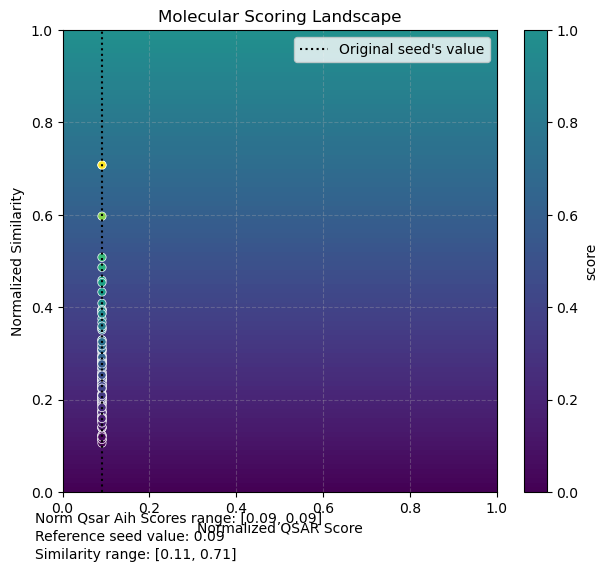

In [19]:
# Get combined scores for point coloring
color_values = -1 * np.array(results.combined_scores)

# Create a uniform grid from 0 to 1
deltas = np.linspace(0, 1, 100)
Xgrid, Ygrid = np.meshgrid(deltas, deltas)

# Calculate scores across the entire grid
#grid_scores, _ = scorer.score_from_properties(similarity_values=Ygrid, qsar_aih_values=Xgrid*scorer.aih_max + scorer.aih_min)
#grid_scores, _ = scorer.score_from_properties(similarity_values=Ygrid, qsar_hsec_values=Xgrid)
#reuse from above

# Plot everything
plt.figure(figsize=(7, 6))

# Plot contour background (0-1 range)
contour = plt.contourf(Xgrid, Ygrid, -1*grid_scores, levels=100, cmap='viridis', vmin=0, vmax=2.0)
plt.colorbar(label='score', ticks=np.linspace(0,2,11))

# Plot reference line for seed value
plt.plot([seed_score, seed_score], [0, 1], linestyle=':', c='k', label="Original seed's value")

# Plot data points (already normalized)
plt.scatter(x_scores, y_scores, c=color_values, edgecolor='white', linewidths=0.5, cmap='viridis')

plt.xlabel("Normalized QSAR Score") 
plt.ylabel("Normalized Similarity")
plt.title("Molecular Scoring Landscape")
plt.legend()
plt.grid(alpha=0.3, linestyle='--')
plt.xlim(0, 1)
plt.ylim(0, 1)

# Add annotations showing ranges and reference value
plt.annotate(f"{metric.replace('_', ' ').title()} range: [{np.min(x_scores):.2f}, {np.max(x_scores):.2f}]",
            xy=(0.05, 0.07), xycoords='figure fraction')

# Add annotation for seed value
plt.annotate(f"Reference seed value: {seed_score:.2f}", 
            xy=(0.05, 0.04), xycoords='figure fraction')

plt.annotate(f"Similarity range: [{np.min(y_scores):.2f}, {np.max(y_scores):.2f}]",
            xy=(0.05, 0.01), xycoords='figure fraction')
    
plt.show()


### Iterative optimization with CMA-ES and the custom oracle function
Now that we have our starting population, we can iteratively optimize using the CMA-ES strategy:

1. Generate a new set of trial encodings
2. Decode and calculate scores
3. Generate a new set of hidden state representations for valid trial candidates
4. Update the CMA-ES optimizer with the current combination of scores and hidden state representations

Note that through the CMA-ES optimization loop, we will occasionally encounter invalid SMILES depending on the search parameters.  We will stop the CMA-ES optimization loop if we have reduced our starting population by half.

In [20]:
popsize

139

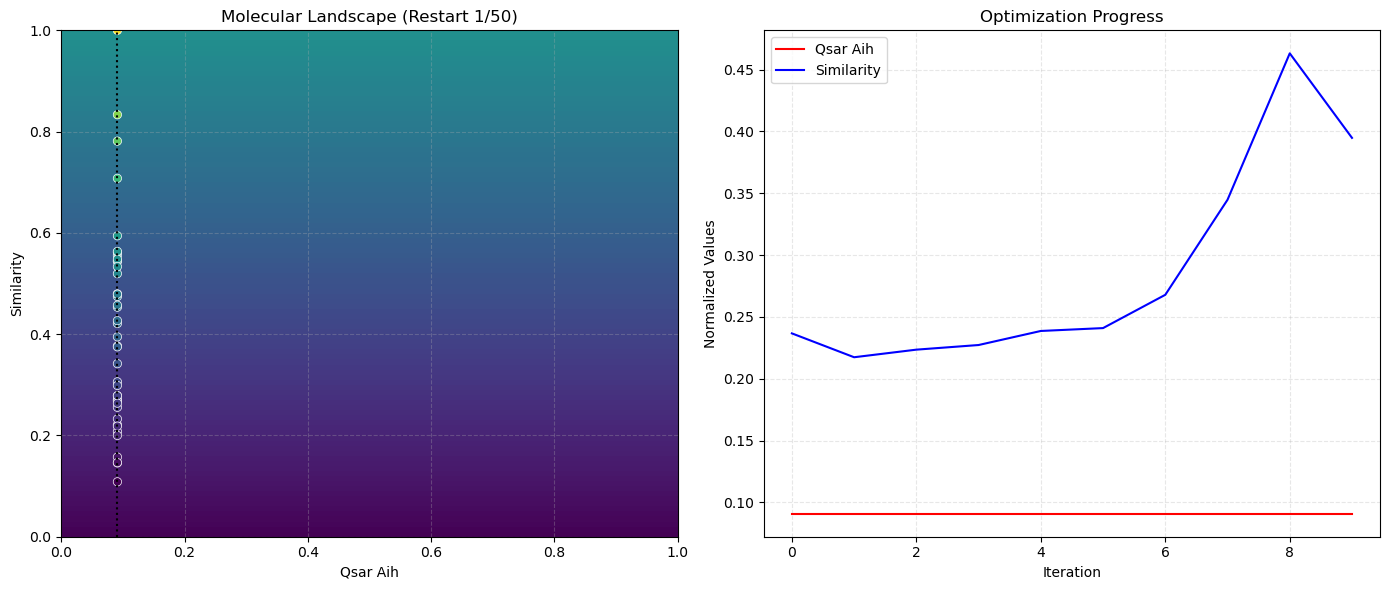

<Figure size 640x480 with 0 Axes>

Restart 1/50, Iter 10/1000, Total: 10/50000
Pop=41, Qsar Aih=0.09, Sim=0.39
Elite solutions: 111, Diverse solutions: 0
Using increased elitism: 8 elite (20.1%) + 33 new solutions
#~now scoring~#
#~Done scoring~#
Elite solutions: 111, best: -1.0000, worst: -0.5139
Skipping iteration - not enough valid molecules (29 < 34)
Using increased elitism: 5 elite (20.1%) + 24 new solutions
#~now scoring~#
#~Done scoring~#
Elite solutions: 111, best: -1.0000, worst: -0.5333
Skipping iteration - not enough valid molecules (20 < 34)
Using increased elitism: 4 elite (20.1%) + 16 new solutions
#~now scoring~#
#~Done scoring~#
Elite solutions: 111, best: -1.0000, worst: -0.5441
Skipping iteration - not enough valid molecules (15 < 34)
Using increased elitism: 3 elite (20.1%) + 12 new solutions
#~now scoring~#
#~Done scoring~#
Elite solutions: 111, best: -1.0000, worst: -0.5441
Skipping iteration - not enough valid molecules (11 < 34)
Including best elite solution in population
#~now scoring~#
#~Done sc

KeyboardInterrupt: 

In [21]:
## 
### New logic analoguos nvidia paper
##

%matplotlib inline
#import numpy as np
#import matplotlib.pyplot as plt
#from IPython.display import clear_output, display
#import cma

from scipy.spatial.distance import pdist, squareform

# Set the normalized metric to use
metric = 'norm_qsar_aih_scores'
raw_metric = metric.replace('norm_', '')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# Optimization parameters from the paper
fixed_popsize = popsize              # Fixed population size as in the paper
iterations_per_restart = 1000    # Iterations per restart
num_restarts = 50                # Number of restarts
total_iterations = iterations_per_restart * num_restarts  # Total iterations (50,000)

# Initialize global best tracking
global_best_score = float('inf')  # For minimization
global_best_molecule = None
global_best_encoding = None

# Initial data for plotting
med_scores = []
med_sims = []
##################


# Main optimization loop with multiple restarts - Enhanced version
import numpy as np
from scipy.spatial.distance import pdist, squareform

# Parameters for the enhanced optimization
initial_popsize = fixed_popsize  # Starting population size
max_popsize = initial_popsize * 2  # Maximum population size after adjustment
min_popsize = initial_popsize  # Minimum population size

# Parameters for diversity-based selection
num_diverse_points = 5  # Number of diverse points to maintain
diversity_weight = 0.3  # Weight for diversity vs score (0-1)

# Parameters for elitism
elitism_ratio = 0.2  # Percentage of best solutions to carry forward

# Storage for diverse solutions
diverse_solutions = []  # Will store (encoding, score, molecule) tuples

for restart in range(num_restarts):
    print(f"\n===== Starting restart {restart+1}/{num_restarts} =====")
    
    # Calculate population size for this restart - increase after initial restarts
    # then gradually decrease back to normal
    if restart < 5:
        current_popsize = min(initial_popsize + restart * 20, max_popsize)
    else:
        current_popsize = max(max_popsize - (restart - 5) * 10, min_popsize)
    
    print(f"Using population size of {current_popsize} for this restart")
    
    # Initialize or reset optimizer for this restart
    if restart == 0:
        # First run - use the pre-defined optimizer with seed
        # The optimizer should already be initialized before this loop
        print("Using pre-initialized optimizer with seed")
    elif len(diverse_solutions) > 0 and restart % 3 != 0:  # Every 3rd restart use diverse point instead of best
        # Select a restart point from our diverse solutions
        # Choose with probability inversely proportional to their scores
        scores = np.array([s[1] for s in diverse_solutions])
        # Invert scores for minimization problems
        inv_scores = 1.0 / (scores + 1e-10)
        probs = inv_scores / np.sum(inv_scores)
        
        selected_idx = np.random.choice(len(diverse_solutions), p=probs)
        selected_encoding = diverse_solutions[selected_idx][0]
        selected_score = diverse_solutions[selected_idx][1]
        selected_molecule = diverse_solutions[selected_idx][2]
        
        print(f"Restarting from diverse solution {selected_idx}:")
        print(f"   Score: {selected_score:.4f}, Molecule: {selected_molecule[:30]}...")
        
        try:
            # REDUCED SIGMA: Use smaller sigma value for closer samples
            sigma = 0.4 * (1 + 0.3 * (restart % 10))  # Significantly reduced sigma
            optimizer = cma.CMAEvolutionStrategy(selected_encoding, sigma, {'popsize': current_popsize})
            print(f"Optimizer restarted with reduced sigma={sigma} using diverse solution")
        except Exception as e:
            print(f"Error restarting from diverse solution: {str(e)}")
            if global_best_encoding is not None:
                optimizer = cma.CMAEvolutionStrategy(global_best_encoding, 0.4, {'popsize': current_popsize})
                print("Falling back to global best encoding with reduced sigma")
            else:
                optimizer = cma.CMAEvolutionStrategy(np.zeros(512), 0.4, {'popsize': current_popsize})
                print("Falling back to zero initialization with reduced sigma")
    elif global_best_encoding is None:
        # If we somehow don't have a best encoding yet, initialize with zeros
        optimizer = cma.CMAEvolutionStrategy(np.zeros(512), 0.4, {'popsize': current_popsize})
        print("No valid best encoding yet, initialized with zeros and reduced sigma")
    else:
        try:
            # Subsequent runs - initialize from global best with REDUCED sigma
            sigma = 0.4 * (1 + 0.3 * (restart % 10))  # REDUCED sigma for closer samples
            optimizer = cma.CMAEvolutionStrategy(global_best_encoding, sigma, {'popsize': current_popsize})
            print(f"Optimizer restarted with reduced sigma={sigma} using global best encoding")
            
            # Generate and decode initial trial encodings with the new optimizer
            print("Generating initial molecules for this restart...")
            
            # Ask for slightly fewer points to leave room for explicitly including elites
            num_direct_samples = current_popsize - min(5, len(elite_solutions))
            trial_encodings = optimizer.ask(num_direct_samples)
            
            # Explicitly include top elite solutions in the initial population
            if elite_solutions:
                num_elites_to_include = min(5, len(elite_solutions))
                elite_encodings = [elite[0] for elite in elite_solutions[:num_elites_to_include]]
                trial_encodings = np.vstack([trial_encodings] + elite_encodings)
                print(f"Explicitly included {num_elites_to_include} elite solutions in initial population")
            
            hiddens_array = np.expand_dims(np.array(trial_encodings), axis=1)
            hiddens_json = {"hiddens": hiddens_array.tolist(),
                           "mask": [[True] for _ in range(hiddens_array.shape[0])]}
            response = requests.post(decode_url, headers={'accept': 'application/json', 'Content-Type': 'application/json'}, json=hiddens_json)
            initial_molecules = list(dict.fromkeys(response.json()['generated']))
            print(f"Generated {len(initial_molecules)} initial molecules for this restart")
            
        except Exception as e:
            print(f"Error restarting optimizer: {str(e)}")
            print("Falling back to zero initialization with reduced sigma")
            optimizer = cma.CMAEvolutionStrategy(np.zeros(512), 0.4, {'popsize': current_popsize})
    
    # Counter for consecutive failed iterations
    consecutive_failures = 0
    max_consecutive_failures = 10  # Maximum allowed consecutive failures
    
    # Track last improvement
    last_improvement_iter = 0
    iterations_without_improvement = 0
    max_iterations_without_improvement = 100
    
    # Maintain a list of elite solutions for this restart
    elite_solutions = []
    
    # Run iterations for this restart
    for i in range(iterations_per_restart):
        # Apply elitism: increased frequency and ratio of elite solutions
        if elite_solutions and np.random.random() < 0.5:  # 50% chance to use elitism (increased from 30%)
            # INCREASED ELITISM: Use more elite solutions in the population
            elitism_ratio_this_iter = elitism_ratio * (1 + 0.5 * (i / iterations_per_restart))  # Gradually increase ratio
            elitism_ratio_this_iter = min(elitism_ratio_this_iter, 0.5)  # Cap at 50% elites
            
            num_elite = int(current_popsize * elitism_ratio_this_iter)
            num_new = current_popsize - num_elite
            
            # Ask for fewer new solutions
            new_trial_encodings = optimizer.ask(num_new)
            
            # Combine with elite solutions (limited by available elite solutions)
            num_elite_available = min(num_elite, len(elite_solutions))
            elite_encodings = [elite[0] for elite in elite_solutions[:num_elite_available]]
            
            # Fill any remaining slots with new solutions if we don't have enough elite solutions
            if num_elite_available < num_elite:
                more_new = optimizer.ask(num_elite - num_elite_available)
                trial_encodings = elite_encodings + new_trial_encodings + more_new
            else:
                trial_encodings = elite_encodings + new_trial_encodings
                
            print(f"Using increased elitism: {num_elite_available} elite ({100*elitism_ratio_this_iter:.1f}%) + {len(new_trial_encodings)} new solutions")
        else:
            # Ask for trial encodings (using current population size)
            # Always include at least one elite solution when available
            if elite_solutions:
                trial_encodings = optimizer.ask(current_popsize - 1)
                # Always include the best elite solution
                best_elite_encoding = elite_solutions[0][0]
                trial_encodings = np.vstack([trial_encodings, best_elite_encoding])
                print(f"Including best elite solution in population")
            else:
                trial_encodings = optimizer.ask(current_popsize)
        
        # Decode to molecules
        hiddens_array = np.expand_dims(np.array(trial_encodings), axis=1)
        hiddens_json = {"hiddens": hiddens_array.tolist(), "mask": [[True] for _ in range(hiddens_array.shape[0])]}
        response = requests.post(decode_url, headers={'accept': 'application/json', 'Content-Type': 'application/json'}, json=hiddens_json)
        
        # Process valid molecules
        molecules = list(dict.fromkeys(response.json()['generated']))
        
        # Filter for valid molecules and check max length
        valid_smiles = []
        max_length = 128  # Maximum length your model can handle
        
        for mol in molecules:
            # Check if it's a valid SMILES and within length limits
            if Chem.MolFromSmiles(mol) is not None and len(mol) <= max_length:
                valid_smiles.append(mol)
            elif len(mol) > max_length:
                print(f"Skipping molecule: exceeds max length ({len(mol)} > {max_length})")
        
        # Handle case with no valid molecules
        if len(valid_smiles) == 0:
            print("No valid molecules in this iteration, skipping...")
            consecutive_failures += 1
            if consecutive_failures >= max_consecutive_failures:
                print(f"Too many consecutive failures ({consecutive_failures}), forcing restart")
                break  # Break out of this restart
            continue
         
        # Get encodings for valid SMILES
        try:
            data = {"sequences": valid_smiles}
            response = requests.post(hidden_url, headers={'accept': 'application/json', 'Content-Type': 'application/json'}, json=data)
            hiddens_array = np.squeeze(np.array(response.json()["hiddens"]))
        except Exception as e:
            print(f"Error when getting encodings: {str(e)}")
            print(f"Checking for problematic sequences...")
            
            # Debug any problematic sequences
            for i, smiles in enumerate(valid_smiles):
                if len(smiles) > 128:
                    print(f"Molecule {i} exceeds length limit: {len(smiles)} chars")
            
            consecutive_failures += 1
            if consecutive_failures >= max_consecutive_failures:
                print(f"Too many consecutive failures ({consecutive_failures}), forcing restart")
                break  # Break out of this restart
            continue  # Skip this iteration
        
        # Score molecules
        results = scorer.score(valid_smiles, reference_smiles=m_seed)
        current_popsize = len(results.combined_scores)
        
        # Update global best if we found a better molecule
        current_best_idx = np.argmin(results.combined_scores)
        current_best_score = results.combined_scores[current_best_idx]
        
        if current_best_score < global_best_score:
            global_best_score = current_best_score
            global_best_molecule = valid_smiles[current_best_idx]
            global_best_encoding = hiddens_array[current_best_idx] if hiddens_array.ndim > 1 else hiddens_array
            print(f"New best score: {global_best_score:.4f}, restart {restart+1}, iteration {i+1}")
            
            # Reset counter since we improved
            last_improvement_iter = i
            iterations_without_improvement = 0
        else:
            iterations_without_improvement += 1
            
        # Update diverse solutions set
        # Extract individual encodings and their scores
        individual_encodings = hiddens_array if hiddens_array.ndim > 1 else np.array([hiddens_array])
        individual_scores = np.array(results.combined_scores)
        
        # Update our diverse solutions repository
        for j in range(min(10, len(individual_scores))):  # Consider top 10 solutions
            idx = np.argsort(individual_scores)[j]
            current_encoding = individual_encodings[idx]
            current_score = individual_scores[idx]
            current_molecule = valid_smiles[idx]
            
            # Skip if this is a bad solution
            if current_score > 1.5 * global_best_score:
                continue
                
            # If we don't have enough diverse solutions yet, just add it
            if len(diverse_solutions) < num_diverse_points:
                diverse_solutions.append((current_encoding, current_score, current_molecule))
            else:
                # Check diversity compared to existing solutions
                distances = []
                for sol_encoding, _, _ in diverse_solutions:
                    dist = np.linalg.norm(current_encoding - sol_encoding)
                    distances.append(dist)
                
                # Compute diversity score (normalized distance to closest point)
                min_distance = min(distances) if distances else 0
                max_possible_dist = np.sqrt(512)  # Rough approximation for max distance in 512-dim space
                diversity_score = min_distance / max_possible_dist
                
                # Compute combined score (lower is better)
                normalized_score = current_score / global_best_score
                combined_score = (1 - diversity_weight) * normalized_score - diversity_weight * diversity_score
                
                # Find the worst existing solution by combined score
                existing_combined_scores = []
                for k, (sol_encoding, sol_score, _) in enumerate(diverse_solutions):
                    sol_normalized_score = sol_score / global_best_score
                    
                    # Calculate distances to other solutions for diversity
                    sol_distances = []
                    for other_encoding, _, _ in diverse_solutions:
                        if not np.array_equal(sol_encoding, other_encoding):
                            dist = np.linalg.norm(sol_encoding - other_encoding)
                            sol_distances.append(dist)
                    
                    sol_diversity = min(sol_distances) / max_possible_dist if sol_distances else 0
                    sol_combined = (1 - diversity_weight) * sol_normalized_score - diversity_weight * sol_diversity
                    existing_combined_scores.append(sol_combined)
                
                # Replace the worst if this new one is better
                if combined_score < max(existing_combined_scores):
                    worst_idx = np.argmax(existing_combined_scores)
                    diverse_solutions[worst_idx] = (current_encoding, current_score, current_molecule)
                    print(f"Updated diverse solution set with score {current_score:.4f}")
        
        # Update elite solutions for this restart with increased retention
        # Sort all solutions by score
        sorted_indices = np.argsort(individual_scores)
        
        # INCREASED ELITE RETENTION: Keep more elite solutions
        # Dynamically increase the number of elites as optimization progresses
        elite_retention_ratio = elitism_ratio * 2  # Double the normal elite ratio
        num_elite_to_keep = max(int(current_popsize * elite_retention_ratio), 5)  # At least 5
        
        # Create or update the elite solutions list
        new_elite = []
        for j in range(min(num_elite_to_keep, len(sorted_indices))):
            idx = sorted_indices[j]
            if hiddens_array.ndim > 1:
                elite_encoding = hiddens_array[idx]
            else:
                elite_encoding = hiddens_array
            elite_score = individual_scores[idx]
            elite_molecule = valid_smiles[idx]
            new_elite.append((elite_encoding, elite_score, elite_molecule))
        
        # Merge with existing elite solutions and sort
        elite_solutions = elite_solutions + new_elite
        elite_solutions.sort(key=lambda x: x[1])  # Sort by score
        
        # Keep more top solutions (increased from previous version)
        max_elites_to_keep = max(int(max_popsize * elite_retention_ratio), 20)  # Keep more elites (at least 20)
        elite_solutions = elite_solutions[:max_elites_to_keep]
        
        # Print statistics about elite solutions
        if len(elite_solutions) > 0:
            best_elite_score = elite_solutions[0][1]
            worst_elite_score = elite_solutions[-1][1]
            print(f"Elite solutions: {len(elite_solutions)}, best: {best_elite_score:.4f}, worst: {worst_elite_score:.4f}")
        
        # Check if we have enough valid solutions for the optimizer
        if len(valid_smiles) >= optimizer.sp.weights.mu:
            optimizer.tell(np.squeeze(np.array(hiddens_array)), results.combined_scores)
            consecutive_failures = 0  # Reset consecutive failures counter
        else:
            print(f"Skipping iteration - not enough valid molecules ({len(valid_smiles)} < {optimizer.sp.weights.mu})")
            consecutive_failures += 1
            if consecutive_failures >= max_consecutive_failures:
                print(f"Too many consecutive failures ({consecutive_failures}), forcing restart")
                break  # Break out of this restart
            continue  # Skip the rest of this iteration
        
        # Check if we should restart due to lack of improvement
        if iterations_without_improvement >= max_iterations_without_improvement:
            print(f"No improvement for {iterations_without_improvement} iterations, forcing restart")
            break
        
        # Extract normalized scores for visualization
        x_scores = np.array(getattr(results, metric))
        y_scores = np.array(results.norm_similarity_scores)
        color_values = -1 * np.array(results.combined_scores)

        # Update tracking for plotting
        med_scores.append(np.median(x_scores))
        med_sims.append(np.median(y_scores))
        
        ##### plots
        # Clear plots
        ax1.clear()
        ax2.clear()
        clear_output(wait=True)
        
        # Create grid for the background
        deltas = np.linspace(0, 1, 100)
        Xgrid, Ygrid = np.meshgrid(deltas, deltas)
        
        # Plot 1: Molecular landscape
        contour = ax1.contourf(Xgrid, Ygrid, -1*grid_scores, levels=100, cmap='viridis', vmin=0, vmax=2.0)
        # Plot reference line for seed value
        ax1.plot([seed_score, seed_score], [0, 1], linestyle=':', c='k', label="Seed")
        
        # Plot data points
        scatter = ax1.scatter(x_scores, y_scores, c=color_values, edgecolor='white', linewidths=0.5, cmap='viridis')
        # Set labels and appearance
        metric_label = metric.replace('norm_', '').replace('_scores', '').replace('_', ' ').title()
        ax1.set_xlabel(f"{metric_label}")
        ax1.set_ylabel("Similarity")
        ax1.set_title(f"Molecular Landscape (Restart {restart+1}/{num_restarts})")
        ax1.grid(alpha=0.3, linestyle='--')
        ax1.set_xlim(0, 1)
        ax1.set_ylim(0, 1)
        
        # Plot 2: Progress tracking
        ax2.plot(med_scores, color='red', label=metric_label)
        ax2.plot(med_sims, color='blue', label='Similarity')
        ax2.set_ylabel("Normalized Values")
        ax2.set_xlabel("Iteration")
        ax2.set_title("Optimization Progress")
        ax2.grid(alpha=0.3, linestyle='--')
        ax2.legend()
        
        # Display figure
        plt.tight_layout()
        display(fig)
        plt.pause(0.1)
        
        # Status update
        total_iter = restart * iterations_per_restart + i + 1
        print(f"Restart {restart+1}/{num_restarts}, Iter {i+1}/{iterations_per_restart}, Total: {total_iter}/{total_iterations}")
        print(f"Pop={current_popsize}, {metric_label}={med_scores[-1]:.2f}, Sim={med_sims[-1]:.2f}")
        print(f"Elite solutions: {len(elite_solutions)}, Diverse solutions: {len(diverse_solutions)}")

# After all restarts, print out the diverse solutions we found
print("\nDiverse high-performing solutions:")
for i, (_, score, molecule) in enumerate(diverse_solutions):
    print(f"{i+1}. Score: {score:.4f}, Molecule: {molecule}")

print("\nOptimization complete!")
print(f"Best molecule found: {global_best_molecule}")
print(f"Best score: {global_best_score:.4f}")

In [22]:
response.json

<bound method Response.json of <Response [500]>>

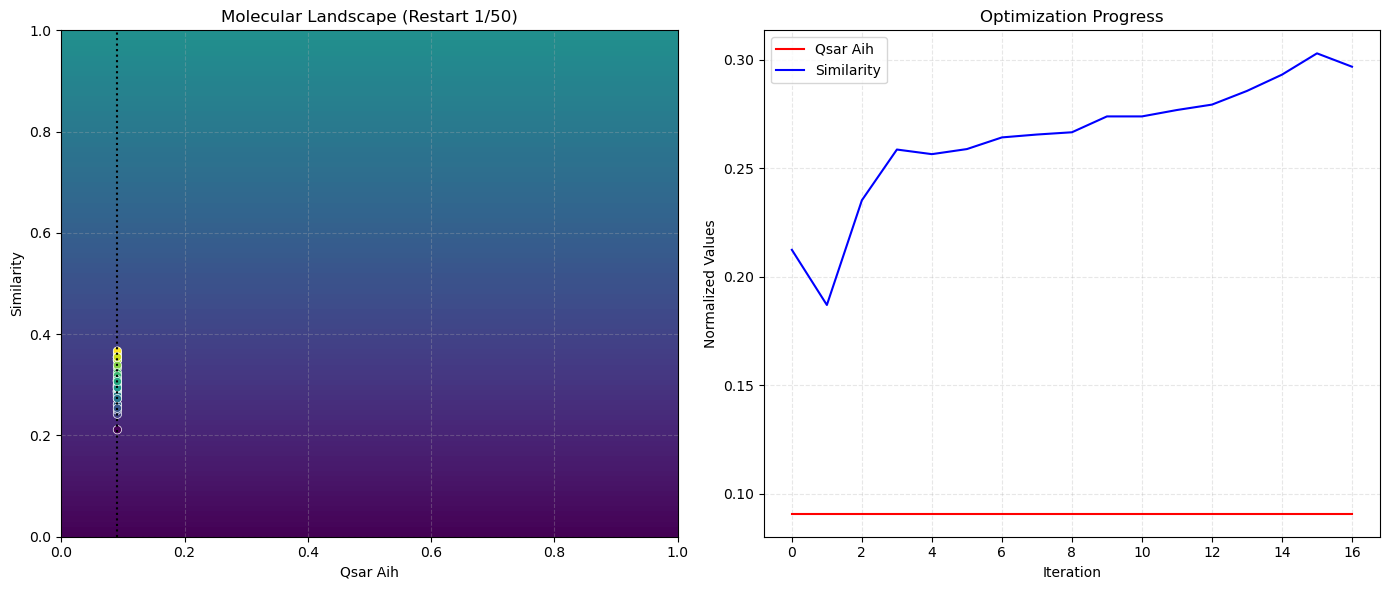

<Figure size 640x480 with 0 Axes>

Restart 1/50, Iter 17/1000, Total: 17/50000
Pop=50, Qsar Aih=0.09, Sim=0.30
#~now scoring~#
#~Done scoring~#
Skipping iteration - not enough valid molecules (48 < 50)
#~now scoring~#
#~Done scoring~#
Skipping iteration - not enough valid molecules (45 < 50)
#~now scoring~#
#~Done scoring~#
Skipping iteration - not enough valid molecules (39 < 50)
#~now scoring~#
#~Done scoring~#
Skipping iteration - not enough valid molecules (36 < 50)
#~now scoring~#
#~Done scoring~#
Skipping iteration - not enough valid molecules (42 < 50)
#~now scoring~#
#~Done scoring~#
Skipping iteration - not enough valid molecules (34 < 50)
#~now scoring~#
#~Done scoring~#
Skipping iteration - not enough valid molecules (41 < 50)
#~now scoring~#
#~Done scoring~#
Skipping iteration - not enough valid molecules (36 < 50)
#~now scoring~#
#~Done scoring~#
Skipping iteration - not enough valid molecules (41 < 50)
#~now scoring~#
#~Done scoring~#
Skipping iteration - not enough valid molecules (44 < 50)
#~now scoring~

In [ ]:
## 
### New logic analoguos nvidia paper
##

%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import clear_output, display
import cma

# Set the normalized metric to use
metric = 'norm_qsar_aih_scores'
raw_metric = metric.replace('norm_', '')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# Optimization parameters from the paper
fixed_popsize = 100               # Fixed population size as in the paper
iterations_per_restart = 1000    # Iterations per restart
num_restarts = 50                # Number of restarts
total_iterations = iterations_per_restart * num_restarts  # Total iterations (50,000)

# Initialize global best tracking
global_best_score = float('inf')  # For minimization
global_best_molecule = None
global_best_encoding = None

# Initial data for plotting
med_scores = []
med_sims = []

# Main optimization loop with multiple restarts
for restart in range(num_restarts):
    print(f"\n===== Starting restart {restart+1}/{num_restarts} =====")
    
    # Initialize or reset optimizer for this restart
    if restart == 0:
        # First run - initialize with zeros or pre-defined starting point
        #optimizer = cma.CMAEvolutionStrategy(np.zeros(512), 1.0, {'popsize': fixed_popsize})
        print("optim already defined")
    else:
        # Subsequent runs - initialize from global best with increased sigma
        sigma = 1.0 * (1 + 0.5 * (restart % 10))  # Vary sigma across restarts
        optimizer = cma.CMAEvolutionStrategy(global_best_encoding, sigma, {'popsize': fixed_popsize})
    
    # Run iterations for this restart
    for i in range(iterations_per_restart):
        # Ask for trial encodings (always use fixed population size)
        trial_encodings = optimizer.ask(fixed_popsize)
        
        # Decode to molecules
        hiddens_array = np.expand_dims(np.array(trial_encodings), axis=1)
        hiddens_json = {"hiddens": hiddens_array.tolist(), "mask": [[True] for _ in range(hiddens_array.shape[0])]}
        response = requests.post(decode_url, headers={'accept': 'application/json', 'Content-Type': 'application/json'}, json=hiddens_json)
        
        # Process valid molecules
        molecules = list(dict.fromkeys(response.json()['generated']))
        valid_smiles = [m for m in molecules if Chem.MolFromSmiles(m) is not None]
        
        # Skip iteration if no valid molecules (rare but possible)
        if len(valid_smiles) == 0:
            print("No valid molecules in this iteraation, skipping...")
            continue
         
        # Get encodings for valid SMILES
        data = {"sequences": valid_smiles}
        response = requests.post(hidden_url, headers={'accept': 'application/json', 'Content-Type': 'application/json'}, json=data)
        hiddens_array = np.squeeze(np.array(response.json()["hiddens"]))
        
        # Score molecules
        results = scorer.score(valid_smiles, reference_smiles=m_seed)
        current_popsize = len(results.combined_scores)
        
        # Update global best if we found a better molecule
        current_best_idx = np.argmin(results.combined_scores)
        current_best_score = results.combined_scores[current_best_idx]
        
        if current_best_score < global_best_score:
            global_best_score = current_best_score
            global_best_molecule = valid_smiles[current_best_idx]
            global_best_encoding = hiddens_array[current_best_idx] if hiddens_array.ndim > 1 else hiddens_array
            print(f"New best score: {global_best_score:.4f}, restart {restart+1}, iteration {i+1}")
        
        # Update optimizer with results (tell can handle variable population sizes)
        #optimizer.tell(np.squeeze(np.array(hiddens_array)), results.combined_scores)
        # Skip tell operation when we don't have enough solutions
        if len(valid_smiles) >= optimizer.sp.weights.mu:
            optimizer.tell(np.squeeze(np.array(hiddens_array)), results.combined_scores)
        else:
            print(f"Skipping iteration - not enough valid molecules ({len(valid_smiles)} < {optimizer.sp.weights.mu})")
            continue  # Skip the rest of this iteration
        
        # Extract normalized scores for visualization
        x_scores = np.array(getattr(results, metric))
        y_scores = np.array(results.norm_similarity_scores)
        color_values = -1 * np.array(results.combined_scores)

        # Update tracking for plotting
        med_scores.append(np.median(x_scores))
        med_sims.append(np.median(y_scores))
        
        ##### plots
        # Clear plots
        ax1.clear()
        ax2.clear()
        clear_output(wait=True)
        
        # Create grid for the background
        deltas = np.linspace(0, 1, 100)
        Xgrid, Ygrid = np.meshgrid(deltas, deltas)
        
        # calc grid scores
        #grid_scores, _ = scorer.score_from_properties(similarity_values=Ygrid, qsar_aih_values=Xgrid)
        #reuse from cell before 

        # Plot 1: Molecular landscape
        contour = ax1.contourf(Xgrid, Ygrid, -1*grid_scores, levels=100, cmap='viridis', vmin=0, vmax=2.0)
        # Plot reference line for seed value
        ax1.plot([seed_score, seed_score], [0, 1], linestyle=':', c='k', label="Seed")
        
        # Plot data points
        scatter = ax1.scatter(x_scores, y_scores, c=color_values, edgecolor='white', linewidths=0.5, cmap='viridis')
        # Set labels and appearance
        metric_label = metric.replace('norm_', '').replace('_scores', '').replace('_', ' ').title()
        ax1.set_xlabel(f"{metric_label}")
        ax1.set_ylabel("Similarity")
        ax1.set_title(f"Molecular Landscape (Restart {restart+1}/{num_restarts})")
        ax1.grid(alpha=0.3, linestyle='--')
        ax1.set_xlim(0, 1)
        ax1.set_ylim(0, 1)
        
        # Plot 2: Progress tracking
        ax2.plot(med_scores, color='red', label=metric_label)
        ax2.plot(med_sims, color='blue', label='Similarity')
        ax2.set_ylabel("Normalized Values")
        ax2.set_xlabel("Iteration")
        ax2.set_title("Optimization Progress")
        ax2.grid(alpha=0.3, linestyle='--')
        ax2.legend()
        
        # Display figure
        plt.tight_layout()
        display(fig)
        plt.pause(0.1)
        
        # Status update
        total_iter = restart * iterations_per_restart + i + 1
        print(f"Restart {restart+1}/{num_restarts}, Iter {i+1}/{iterations_per_restart}, Total: {total_iter}/{total_iterations}")
        print(f"Pop={current_popsize}, {metric_label}={med_scores[-1]:.2f}, Sim={med_sims[-1]:.2f}")

print("\nOptimization complete!")
print(f"Best molecule found: {global_best_molecule}")
print(f"Best score: {global_best_score:.4f}")

## old

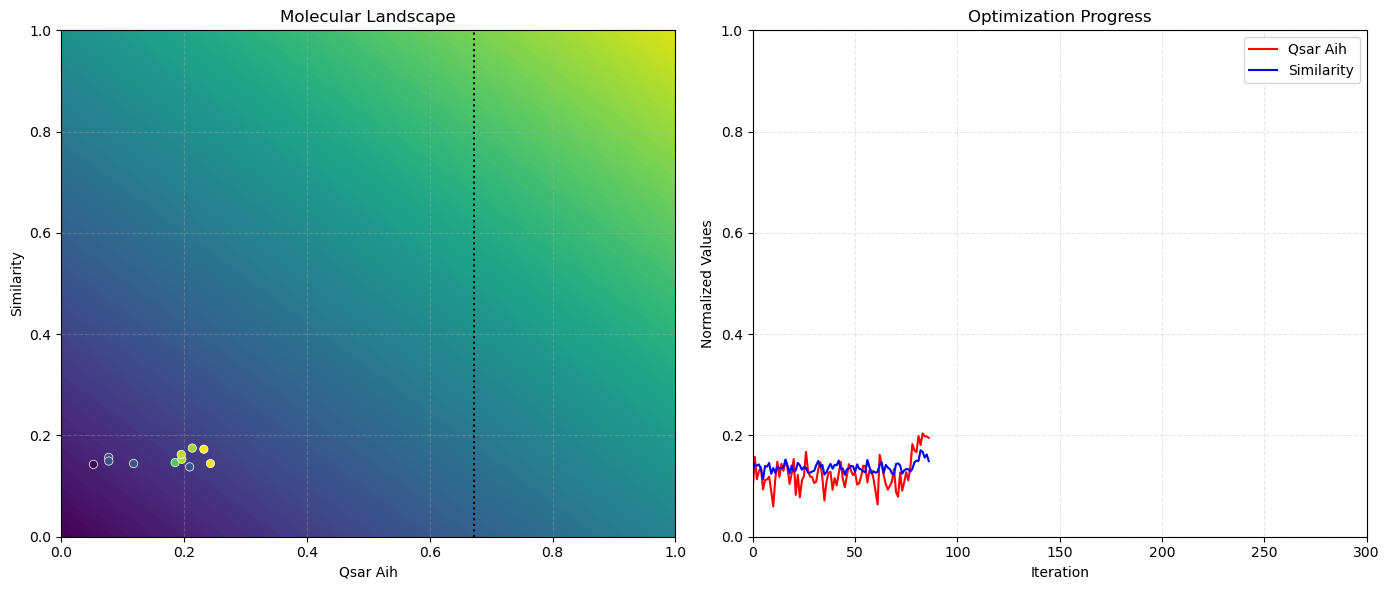

<Figure size 640x480 with 0 Axes>

Iter 86/300: Pop=11, Qsar Aih=0.20, Sim=0.15
#~now scoring~#
#~Done scoring~#
Stopping at minimum population size 8

Optimization complete!


In [20]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import clear_output, display

# Set the normalized metric to use
metric = 'norm_qsar_aih_scores'
raw_metric = metric.replace('norm_', '')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# Initialize tracking lists for median values
med_scores = [np.median(np.array(getattr(results, metric)))]
med_sims = [np.median(np.array(results.norm_similarity_scores))]

# Set parameters for optimization
minpopsize = popsize/2
n_steps = 300
original_popsize = popsize
max_restarts = 50
restart_count = 0
sigma_increase_factor = 1.5  # Increase sigma by 50% on each restart

# store vars
res_store_cscore = []
res_store_qsar = []

for i in range(n_steps): 
    # Ask for trial encodings   
    trial_encodings = optimizer.ask(popsize)
    # Decode to molecules
    hiddens_array = np.expand_dims(np.array(trial_encodings), axis=1)
    hiddens_json = {"hiddens": hiddens_array.tolist(), "mask": [[True] for _ in range(hiddens_array.shape[0])]}
    response = requests.post(decode_url, headers={'accept': 'application/json', 'Content-Type': 'application/json'}, json=hiddens_json)
    # Process valid molecules
    molecules = list(dict.fromkeys(response.json()['generated']))
    valid_smiles = [m for m in molecules if Chem.MolFromSmiles(m) is not None]
    # Get encodings for valid SMILES
    data = {"sequences": valid_smiles}
    response = requests.post(hidden_url, headers={'accept': 'application/json', 'Content-Type': 'application/json'}, json=data)
    hiddens_array = np.squeeze(np.array(response.json()["hiddens"]))
    
    # Score molecules
    results = scorer.score(valid_smiles, reference_smiles=m_seed)
    popsize = len(results.combined_scores)

    # add scores to storage
    #res_store_cscore = res_store_cscore + results.combined_scores
    #res_store_qsar = res_store_qsar + results.norm_qsar_aih_scores
    
    # Check population size
    if popsize <= minpopsize:
        print(f"Stopping at minimum population size {popsize}")
        break
    
    # Update optimizer
    print(f"mean score: {np.mean(np.array(results.combined_scores))}")
    optimizer.tell(np.squeeze(np.array(hiddens_array)), results.combined_scores)
    
    # Extract normalized scores
    x_scores = np.array(getattr(results, metric))
    y_scores = np.array(results.norm_similarity_scores)
    color_values = -1 * np.array(results.combined_scores)

    ##### plots
    # Clear plots
    ax1.clear()
    ax2.clear()
    clear_output(wait=True)
    
    # Create grid for the background
    deltas = np.linspace(0, 1, 100)
    Xgrid, Ygrid = np.meshgrid(deltas, deltas)
    
    # calc grid scores ######## !!! ADAPT when change metric
    #grid_scores, _ = scorer.score_from_properties(similarity_values=Ygrid, qsar_hsec_values=Xgrid)
    grid_scores, _ = scorer.score_from_properties(similarity_values=Ygrid, qsar_aih_values=Xgrid*scorer.aih_max + scorer.aih_min)
    
    # Plot 1: Molecular landscape
    contour = ax1.contourf(Xgrid, Ygrid, -1*grid_scores, levels=100, cmap='viridis', vmin=0, vmax=2.0)
    # Plot reference line for seed value (assuming it's already normalized)
    ax1.plot([seed_score, seed_score], [0, 1], linestyle=':', c='k', label="Seed")
    
    # Plot data points
    scatter = ax1.scatter(x_scores, y_scores, c=color_values, edgecolor='white', linewidths=0.5, cmap='viridis')
    # Set labels and appearance
    metric_label = metric.replace('norm_', '').replace('_scores', '').replace('_', ' ').title()
    ax1.set_xlabel(f"{metric_label}")
    ax1.set_ylabel("Similarity")
    ax1.set_title("Molecular Landscape")
    ax1.grid(alpha=0.3, linestyle='--')
    ax1.set_xlim(0, 1)
    ax1.set_ylim(0, 1)
    # Update tracking lists
    med_scores.append(np.median(x_scores))
    med_sims.append(np.median(y_scores))
    
    # Plot 2: Progress tracking
    ax2.plot(med_scores, color='red', label=metric_label)
    ax2.plot(med_sims, color='blue', label='Similarity')
    ax2.set_ylabel("Normalized Values")
    ax2.set_xlabel("Iteration")
    ax2.set_xlim(0, n_steps)
    ax2.set_ylim(0, 1)
    ax2.grid(alpha=0.3, linestyle='--')
    ax2.legend()
    ax2.set_title("Optimization Progress")
    
    # Display figure
    plt.tight_layout()
    display(fig)
    plt.pause(0.1)
    
    print(f"Iter {i+1}/{n_steps}: Pop={popsize}, {metric_label}={med_scores[-1]:.2f}, Sim={med_sims[-1]:.2f}")

print("\nOptimization complete!")

In [73]:
metric

'norm_qsar_aih_scores'

## Viewing the resulting optimized molecules.

In [27]:
len(elite_solutions)

60

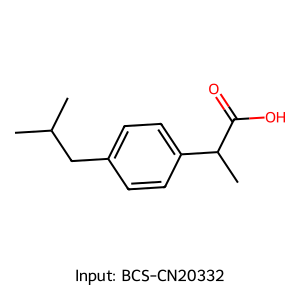

In [28]:
input_mol = Chem.MolFromSmiles(m_seed)

Draw.MolToImage(input_mol, legend=str(f"Input: {m_seed_name}" ), subImgSize=(350,360))

In [36]:
elite_solutions[0][2]

'CCC[C@@H](C)NC(=O)Nc1ccccc1'

In [37]:
Draw.MolsToGridImage([Chem.MolFromSmiles(smile, sanitize=False) for smile in elite_solutions[:5][2]],
                     legends=molecules, molsPerRow=4, subImgSize=(300, 300))

TypeError: No registered converter was able to produce a C++ rvalue of type std::basic_string<wchar_t, std::char_traits<wchar_t>, std::allocator<wchar_t> > from this Python object of type numpy.ndarray

In [35]:
list_w_seed

['CC(C)(C)OC(=O)N1C[C@H]2C[C@H]1[C@@H]2CNC1CC(N2CC[C@@H](O)C2)C1',
 'COc1cccc(OC(C)C)c1NC(=O)N1CCCc2ccccc21',
 'COC(=O)[C@](C)(CCN(C)C(=O)c1cc2ccccc2c(=O)o1)NC(=O)OC(C)(C)C',
 'COCc1cccc(C(=O)N2CC[C@H](CNCc3ncc(C)o3)C2)c1',
 'C[C@@H](CNC(=O)C1CC2(CC2)C1)N(C)C(=O)c1cc(-c2nn[nH]n2)c[nH]1',
 'O=C(N[C@H]1[C@@H]2CN(C(=O)[C@H]3CCOC3)C[C@@H]21)c1cc2[nH]ccc2s1',
 'CCc1cc(C(=O)N[C@@H]2CCCCN(C(=O)c3cocc3C)C2)n[nH]1',
 'COC(=O)[C@@H](NCCOC1CCC1)c1ccc([N+](=O)[O-])cc1',
 'CCC[C@H](C(=O)N[C@@H](C)CNC(=O)C1CS(=O)(=O)C1)C(C)C',
 'COc1cc(-c2nn[nH]n2)ccc1CNCCNC(=O)C[C@H]1CCCO1',
 'C[C@@H](NC(=O)NCc1cccc2c1OCCCO2)[C@H]1CCCOC1',
 'CC(C)C(=O)Nc1ccc(NC(=O)NC[C@@H](CO)[C@H]2CCOC2)cc1',
 'COC(=O)c1ccc(NC(=O)c2cncc(OC(C)(C)C)c2)cc1',
 'COC(=O)CN(C)C[C@H]1C[C@@H]1C(=O)Nc1cccc(F)c1F',
 'CCC(=O)N1CCCN(c2nnc(C3CC3)n2C)CC1',
 'CC(C)(C)OC(=O)N1CC(C)(NC(=O)COCCCCn2ccnc2)C1',
 'COc1ccc(OS(=O)(=O)c2cc(C(=O)N[C@@H](C)C(=O)NCc3ccccc3)no2)cc1',
 'Cc1ccc(C(=O)NC2CN(C(=O)CNC(=O)c3cccs3)C2)nc1',
 'COc1ccc(OC)c(CNC(=O)Nc2ccc


--> Test mit 'COc1cc(-c2nn[nH]n2)ccc1CNCCNC(=O)C[C@H]1CCCO1'
--> Add Cl instead of CO --> 'Clc1cc(-c2nn[nH]n2)ccc1CNCCNC(=O)C[C@H]1CCCO1'




In [52]:
#manuel adjust seed score
adjusted = "Clc1cc(-c2nn[nH]n2)ccc1CNCCNC(=O)C[C@H]"
result_score_adjusted = scorer.score([adjusted], reference_smiles=m_seed)
print (adjusted)
print (result_score_adjusted)

#~now scoring~#
#~Done scoring~#
Clc1cc(-c2nn[nH]n2)ccc1CNCCNC(=O)C[C@H]
ScoringResults(combined_scores=array([-0.08]), logp_scores=[0.0], similarity_scores=[0.2], qsar_hsec_scores=[0.0], qsar_aih_scores=[-1.27], qed_scores=[0.0], norm_logp_scores=[0.3], norm_similarity_scores=[0.2], norm_qsar_hsec_scores=[0.03225806451612903], norm_qsar_aih_scores=[0.0], norm_qed_scores=[0.0])


In [36]:
list_w_seed = valid_smiles + [m_seed]

In [34]:
# Test molecule scoring and access predictions and metrics
results_score = scorer.score(list_w_seed, reference_smiles=m_seed)
final_scores = results_score.norm_qsar_aih_scores[0]
print(f"QSAR-SIP: {results_score.qsar_aih_scores}")
print("####")
print(f"QSAR-SIP Normalized: {results_score.norm_qsar_aih_scores}")

#~now scoring~#
#~Done scoring~#
QSAR-SIP: [19.34, -0.18, 34.01, 46.58, 21.15, 46.92, 2.63, 25.43, -13.33, 23.7, 41.8, -7.08, 32.69, 1.78, 46.07, -28.55, 3.1, 10.58, 33.77, 23.78, 2.38, -44.4, -5.02, 8.59, -8.22, -27.39, 38.13, -42.46, 2.89, 29.89, -8.74, 31.06, 43.49, -14.44, 37.09, -52.03, 57.88, 1.25, -18.59, -13.53, -31.23, -5.18, 31.64, 2.65, -24.71, 27.81, 48.24, 7.96, -7.43, 18.08, 63.71, 46.22, 3.82, 4.56, -11.19, -39.76, 12.01, 34.19, 32.5, 24.52, -28.41, -17.31, -6.38, 24.9, -3.79, -23.98, -8.31, -4.04, -18.43, -19.67, 5.32, 16.9, -30.31, 7.74, -5.1, 30.03, 11.38, 56.38, 31.76, -1.77, -23.16, 66.66, -16.68, -8.22, -31.79, -36.17, 38.28, -17.24, 60.77, 27.63, 252.43]
####
QSAR-SIP Normalized: [0.04835, 0.0, 0.08502499999999999, 0.11645, 0.052875, 0.1173, 0.006575, 0.06357499999999999, 0.0, 0.05925, 0.1045, 0.0, 0.08172499999999999, 0.00445, 0.115175, 0.0, 0.00775, 0.02645, 0.08442500000000001, 0.05945, 0.0059499999999999996, 0.0, 0.0, 0.021475, 0.0, 0.0, 0.09532500000000001, 0

In [30]:
seed_score


0.631075

asdfasd

In [ ]:
### code Gil



In [31]:
import pandas as pd
df = pd.DataFrame({"valid_smiles": valid_smiles })

In [32]:
import helper
df['LogP'] = df['valid_smiles'].apply(helper.calculate_logp)
df['QED'] = df['valid_smiles'].apply(helper.calculate_qed)

In [33]:
df.sort_values(["QED"], inplace=True, ascending=False)
df.head(10)

,valid_smiles,LogP,QED
37,Cc1csc(C(=O)N2CC[C@H](NC(=O)c3ccco3)C2)c1,2.29402,0.946098
19,Cc1ccccc1CN1CC[C@@H](NC(=O)c2ccccc2)C[C@H]1C,3.77792,0.928940
31,Cc1cc(C(=O)N2CC[C@@H](NC(=O)[C@@H]3C[C@H]3c3cc...,2.52442,0.922549
52,Cc1ccc(O[C@@H](C)C(=O)NN2CCCc3cc(F)c(F)cc32)cc1,3.52452,0.920901
51,COC1(C(=O)N2CC[C@H]3CCN(C(=O)c4ccc[nH]4)[C@H]3...,1.64680,0.915716
6,COCC(C)(C)C(=O)Nc1nc(C(C)(C)C)cs1,3.05170,0.914528
9,CS(=O)(=O)N1CCC[C@H](CNC(=O)c2ccc(F)cc2)C1,1.22710,0.908734
50,COCCC(=O)N[C@@H]1CC[C@H](C)N(C(=O)c2ccc(F)cc2)C1,1.97150,0.901551
89,CCc1cc(C(=O)N2CC[C@H](NC(=O)c3cccs3)C2)n[nH]1,1.67810,0.900069
40,COCCC(=O)N1CC[C@H](NC(=O)c2ccc(F)cc2)[C@H](C)C1,1.82900,0.899606


In [34]:
#df.to_csv('../../data/interim/molmim/guided/molmmim_QSAR_AIH_BCS-CN20332.csv', index=False, sep=';', header=True, mode='x') 
#../../data/interim/molmmim_BCS-CN20332_LogP_sim03_100p_100m
#../../data/interim/XXX.csv

## Second Seed